# 0. Cargar Librerias
python -m pip install pandas numpy matplotlib seaborn scikit-learn pyarrow jupyter ipykernel

# 1. Importar Librerías


In [3]:
import pandas as pd

# URL del dataset NYC Yellow Taxi (agosto de 2026)
url = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2026-08.parquet"

# Descargar y cargar el dataset
df = pd.read_parquet(url)

# Mostrar las dimensiones
print("Registros:", df.shape[0])
print("Variables:", df.shape[1])

# Visualizar los primeros registros
display(df.head())

Registros: 3336716
Variables: 21


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,request_source
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,N,140,262,1,...,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,NaN
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,N,140,262,1,...,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,NaN
2,1,2026-08-01 00:54:51,2026-08-01 01:01:07,1.0,1.10,1.0,N,140,263,1,...,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,NaN
3,2,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,N,164,80,1,...,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,NaN
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,N,148,141,1,...,1.0,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,NaN


In [2]:
memoria_mb = df.memory_usage(deep=True).sum() / 1024**2

print(f"Memoria utilizada: {memoria_mb:.2f} MB")

Memoria utilizada: 504.04 MB


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3336716 entries, 0 to 3336715
Data columns (total 21 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     str           
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee            float64   

In [4]:
# Contar valores nulos por columna
print("\nVALORES NULOS")
print(df.isnull().sum())

# Contar registros duplicados
print("\nREGISTROS DUPLICADOS")
print(df.duplicated().sum())


VALORES NULOS
VendorID                       0
tpep_pickup_datetime           0
tpep_dropoff_datetime          0
passenger_count           921181
trip_distance                  0
RatecodeID                921181
store_and_fwd_flag        921181
PULocationID                   0
DOLocationID                   0
payment_type                   0
fare_amount                    0
extra                          0
mta_tax                        0
tip_amount                     0
tolls_amount                   0
improvement_surcharge          0
total_amount                   0
congestion_surcharge      921181
Airport_fee               921181
cbd_congestion_fee             0
request_source           2415867
dtype: int64

REGISTROS DUPLICADOS
7


In [5]:
columnas = [
    "passenger_count",
    "RatecodeID",
    "store_and_fwd_flag",
    "congestion_surcharge",
    "Airport_fee"
]

# Verificar si los nulos coinciden en las mismas filas
patron_nulos = df[columnas].isna()

print(patron_nulos.eq(patron_nulos.iloc[:, 0], axis=0).all().all())

True


In [6]:
pd.crosstab(
    df["passenger_count"].isna(),
    df["request_source"].isna(),
    rownames=["Passenger Count es nulo"],
    colnames=["Request Source es nulo"]
)

Request Source es nulo,False,True
Passenger Count es nulo,,
False,0,2415535
True,920849,332


In [7]:
df["request_source"].value_counts(dropna=False)

request_source
NaN       2415867
HV0003     628774
HV0005     181233
A          103753
EH0004       6253
CC            573
EH0010        263
Name: count, dtype: int64

In [8]:
df = df.drop(columns=["request_source"])

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3336716 entries, 0 to 3336715
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     str           
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee            float64   

In [17]:
df.isnull().sum()

VendorID                      0
tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          921181
trip_distance                 0
RatecodeID               921181
PULocationID                  0
DOLocationID                  0
payment_type                  0
fare_amount                   0
extra                         0
mta_tax                       0
tip_amount                    0
tolls_amount                  0
improvement_surcharge         0
total_amount                  0
congestion_surcharge     921181
Airport_fee              921181
cbd_congestion_fee            0
dtype: int64

In [2]:
df.info()

NameError: name 'df' is not defined

In [16]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140,262,1,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140,262,1,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00
2,1,2026-08-01 00:54:51,2026-08-01 01:01:07,1.0,1.10,1.0,140,263,1,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00
3,2,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164,80,1,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148,141,1,20.5,1.0,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75


In [4]:
df = df.drop(columns=["store_and_fwd_flag"])

In [26]:
df["passenger_count"].unique().tolist()

[1.0, 2.0, 4.0, 3.0, 0.0, 5.0, 6.0, 8.0, nan]

In [5]:
df = df.dropna().reset_index(drop=True)

Revisar inconsistencia de 4 variables:

- Distancia: valores negativos o iguales a cero.
- Tarifa: valores negativos.
- Pasajeros: valores negativos, fraccionarios o excesivamente altos.
- Duración: viajes con duración negativa o igual a cero.

Como nuestro objetivo es segmentar viajes según sus características, propondría considerar válidos únicamente los registros que cumplan estas condiciones:
- Distancia mayor que cero.
- Tarifa mayor o igual que cero.
- Número de pasajeros mayor que cero.
- Duración mayor que cero.

In [29]:
# Calcular duración de los viajes en minutos
duracion = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

# Revisar posibles inconsistencias
print("Distancias negativas:", (df["trip_distance"] < 0).sum())
print("Distancias iguales a cero:", (df["trip_distance"] == 0).sum())

print("Tarifas negativas:", (df["fare_amount"] < 0).sum())

print("Pasajeros negativos:", (df["passenger_count"] < 0).sum())
print("Pasajeros iguales a cero:", (df["passenger_count"] == 0).sum())
print("Pasajeros mayores a 8:", (df["passenger_count"] > 8).sum())
print("Pasajeros fraccionarios:", (df["passenger_count"] % 1 != 0).sum())

print("Duraciones negativas:", (duracion < 0).sum())
print("Duraciones iguales a cero:", (duracion == 0).sum())

Distancias negativas: 0
Distancias iguales a cero: 37307
Tarifas negativas: 14014
Pasajeros negativos: 0
Pasajeros iguales a cero: 7478
Pasajeros mayores a 8: 0
Pasajeros fraccionarios: 0
Duraciones negativas: 2
Duraciones iguales a cero: 43171


In [6]:
df["trip_duration"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

In [8]:
#introducir nulos
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

# Crear una copia para conservar el DataFrame original
df_examen = df.copy()

# Porcentaje de registros a modificar
porcentaje = 0.005

# Cantidad de registros
n = int(len(df_examen) * porcentaje)

# Introducir valores nulos en todas las columnas excepto VendorID
for columna in df_examen.columns:
    if columna != "VendorID":
        indices = rng.choice(df_examen.index, size=n, replace=False)
        df_examen.loc[indices, columna] = np.nan

# Modificar aleatoriamente VendorID usando valores existentes
indices = rng.choice(df_examen.index, size=n, replace=False)

valores_vendor = df_examen["VendorID"].dropna().unique()

df_examen.loc[indices, "VendorID"] = rng.choice(
    valores_vendor,
    size=n,
    replace=True
)

# Verificar los nulos
print(df_examen.isna().sum())

VendorID                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
trip_distance            0
RatecodeID               0
PULocationID             0
DOLocationID             0
payment_type             0
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
congestion_surcharge     0
Airport_fee              0
cbd_congestion_fee       0
request_source           0
trip_duration            0
dtype: int64


In [9]:
# Cantidad de registros a duplicar
n_duplicados = int(len(df_examen) * 0.005)

# Seleccionar registros aleatorios
duplicados = df_examen.sample(
    n=n_duplicados,
    random_state=42
)

# Agregar los registros duplicados
df_examen = pd.concat(
    [df_examen, duplicados],
    ignore_index=True
)

# Verificar resultados
print("Registros originales:", len(df))
print("Registros duplicados agregados:", n_duplicados)
print("Registros finales:", len(df_examen))
print("Duplicados detectados:", df_examen.duplicated().sum())

Registros originales: 0
Registros duplicados agregados: 0
Registros finales: 0
Duplicados detectados: 0


In [10]:
#introducir valores inconsistentes en las 4 variables seleccionadas
import numpy as np

rng = np.random.default_rng(42)

# Cantidad total de registros a modificar (0.5 %)
n = int(len(df_examen) * 0.005)

# Seleccionar índices aleatorios sin repetición
indices = rng.choice(df_examen.index, size=n, replace=False)

# Dividir los índices entre las cuatro variables
idx_distancia, idx_pasajeros, idx_tarifa, idx_duracion = np.array_split(
    indices, 4
)

# 1. Distancias negativas
df_examen.loc[idx_distancia, "trip_distance"] = rng.uniform(
    -100, -1, size=len(idx_distancia)
)

# 2. Pasajeros negativos o iguales a 100
df_examen.loc[idx_pasajeros, "passenger_count"] = rng.choice(
    [-5, -3, -1, 100],
    size=len(idx_pasajeros)
)

# 3. Tarifas iguales o mayores a 10,000
df_examen.loc[idx_tarifa, "fare_amount"] = rng.uniform(
    10000, 20000, size=len(idx_tarifa)
)

# 4. Duraciones negativas
df_examen.loc[idx_duracion, "trip_duration"] = rng.uniform(
    -300, -1, size=len(idx_duracion)
)

print("Registros modificados:", n)

Registros modificados: 0


In [35]:
#verificar inconsistencias
print("Distancias negativas:",
      (df_examen["trip_distance"] < 0).sum())

print("Pasajeros negativos o iguales a 100:",
      ((df_examen["passenger_count"] < 0) |
       (df_examen["passenger_count"] == 100)).sum())

print("Tarifas >= 10000:",
      (df_examen["fare_amount"] >= 10000).sum())

print("Duraciones negativas:",
      (df_examen["trip_duration"] < 0).sum())

Distancias negativas: 3035
Pasajeros negativos o iguales a 100: 3035
Tarifas >= 10000: 3034
Duraciones negativas: 3036


In [37]:
df_examen[df_examen["trip_duration"]<0].head(3)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
1006,2,2026-08-01 00:35:30,2026-08-01 01:09:13,1.0,4.71,1.0,211.0,142.0,2.0,31.7,1.0,0.5,0.00,0.0,1.0,37.45,2.5,0.0,0.75,-217.198255
1374,2,2026-08-01 00:20:00,2026-08-01 00:33:13,1.0,2.06,1.0,114.0,137.0,1.0,13.5,1.0,0.5,2.00,0.0,1.0,21.25,2.5,0.0,0.75,-228.624929
2397,2,2026-08-01 00:33:08,2026-08-01 00:53:28,1.0,2.71,1.0,158.0,261.0,1.0,19.1,1.0,0.5,4.97,0.0,1.0,29.82,2.5,0.0,0.75,-79.368327


In [38]:
df_examen.info()

<class 'pandas.DataFrame'>
RangeIndex: 2427612 entries, 0 to 2427611
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   PULocationID           float64       
 7   DOLocationID           float64       
 8   payment_type           float64       
 9   fare_amount            float64       
 10  extra                  float64       
 11  mta_tax                float64       
 12  tip_amount             float64       
 13  tolls_amount           float64       
 14  improvement_surcharge  float64       
 15  total_amount           float64       
 16  congestion_surcharge   float64       
 17  Airport_fee            float64       
 18  cbd_congestion_fee     float64   

In [39]:
from pathlib import Path

# Crear la carpeta si no existe
Path("../data/processed").mkdir(parents=True, exist_ok=True)

# Guardar el dataset para el examen
df_examen.to_csv(
    "../data/processed/nyc_taxi_examen.csv",
    index=False
)

In [11]:
from pathlib import Path

# Crear las carpetas si no existen
Path("../data/raw").mkdir(parents=True, exist_ok=True)
Path("../data/processed").mkdir(parents=True, exist_ok=True)

# Guardar el DataFrame original
df.to_parquet(
    "../data/raw/nyc_taxi_original.parquet",
    index=False
)

# Guardar el DataFrame modificado para el examen
df_examen.to_parquet(
    "../data/processed/nyc_taxi_examen.parquet",
    index=False
)

In [1]:
import pandas as pd
ruta = "../data/processed/nyc_taxi_examen.parquet"

df = pd.read_parquet(ruta)

In [4]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,...,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,request_source,trip_duration


In [3]:
df.shape

(0, 21)

In [2]:
df["payment_type"].value_counts(dropna=False)

Series([], Name: count, dtype: int64)

In [5]:
from pathlib import Path

ruta = Path("../data/processed/nyc_taxi_examen.parquet")

print("Ruta absoluta:", ruta.resolve())
print("¿Existe el archivo?", ruta.exists())
print("Tamaño (MB):", ruta.stat().st_size / (1024**2))
print("Dimensiones:", df.shape)
print("Columnas:", df.columns.tolist())

Ruta absoluta: /Users/lizette/Coding/bigdata/examen2parcial/data/processed/nyc_taxi_examen.parquet
¿Existe el archivo? True
Tamaño (MB): 0.0098724365234375
Dimensiones: (0, 21)
Columnas: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'request_source', 'trip_duration']


In [6]:
import pyarrow.parquet as pq

archivo = pq.ParquetFile(ruta)

print("Registros almacenados:", archivo.metadata.num_rows)
print("Columnas almacenadas:", archivo.metadata.num_columns)

Registros almacenados: 0
Columnas almacenadas: 21


In [7]:
from pathlib import Path

ruta_csv = Path("../data/processed/nyc_taxi_examen.csv")

print("¿Existe el archivo?", ruta_csv.exists())
print("Tamaño (MB):", round(ruta_csv.stat().st_size / (1024**2), 2))

# Contar registros sin cargar el DataFrame
with open(ruta_csv, "r", encoding="utf-8") as archivo:
    registros = sum(1 for linea in archivo) - 1

print("Registros:", registros)

¿Existe el archivo? True
Tamaño (MB): 296.45
Registros: 2427612


In [8]:
import pandas as pd

ruta_csv = "../data/processed/nyc_taxi_examen.csv"

df = pd.read_csv(
    ruta_csv,
    parse_dates=[
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime"
    ]
)

print(df.shape)
print(df.info())

(2427612, 20)
<class 'pandas.DataFrame'>
RangeIndex: 2427612 entries, 0 to 2427611
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   PULocationID           float64       
 7   DOLocationID           float64       
 8   payment_type           float64       
 9   fare_amount            float64       
 10  extra                  float64       
 11  mta_tax                float64       
 12  tip_amount             float64       
 13  tolls_amount           float64       
 14  improvement_surcharge  float64       
 15  total_amount           float64       
 16  congestion_surcharge   float64       
 17  Airport_fee            float64       
 18  cbd_congestion_fee 

In [9]:
ruta_parquet = "../data/processed/nyc_taxi_examen.parquet"

df.to_parquet(
    ruta_parquet,
    index=False
)

In [10]:
import pyarrow.parquet as pq

archivo = pq.ParquetFile(ruta_parquet)

print("Registros:", archivo.metadata.num_rows)
print("Columnas:", archivo.metadata.num_columns)

Registros: 2427612
Columnas: 20


In [14]:
df["payment_type"].value_counts(dropna=False).sort_index()

payment_type
1.0    2051983
2.0     329533
3.0      10413
4.0      23558
NaN      12125
Name: count, dtype: int64

In [15]:
# Diccionario de tipos de pago
tipos_pago = {
    1: "Credit card",
    2: "Cash",
    3: "No charge",
    4: "Dispute"
}

# Reemplazar códigos por descripciones
df["payment_type"] = df["payment_type"].map(tipos_pago)

In [17]:
df["payment_type"].value_counts(dropna=False).sort_index

<bound method Series.sort_index of payment_type
Credit card    2051983
Cash            329533
Dispute          23558
NaN              12125
No charge        10413
Name: count, dtype: int64>

In [18]:
df.to_csv("../data/processed/nyc_taxi_examen.csv", index=False)

df.to_parquet("../data/processed/nyc_taxi_examen.parquet", index=False)

In [20]:
print("Dimensiones:", df.shape)

print("\nValores nulos por columna:")
print(df.isna().sum())


Dimensiones: (2427612, 20)

Valores nulos por columna:
VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64


In [21]:

print("\nRegistros duplicados:")
print(df.duplicated().sum())

print("\nValores inconsistentes:")
print("Distancias negativas:", (df["trip_distance"] < 0).sum())

print(
    "Pasajeros negativos o iguales a 100:",
    ((df["passenger_count"] < 0) |
     (df["passenger_count"] == 100)).sum()
)

print("Tarifas >= 10000:", (df["fare_amount"] >= 10000).sum())

print("Duraciones negativas:", (df["trip_duration"] < 0).sum())


Registros duplicados:
11961

Valores inconsistentes:
Distancias negativas: 3035
Pasajeros negativos o iguales a 100: 3035
Tarifas >= 10000: 3034
Duraciones negativas: 3036


In [23]:
# Crear una copia del DataFrame original
df_limpio = df.copy()

# 1. Eliminar registros duplicados
df_limpio = df_limpio.drop_duplicates()

# 2. Eliminar registros con valores nulos
df_limpio = df_limpio.dropna()

# 3. Eliminar registros inconsistentes
df_limpio = df_limpio[
    (df_limpio["trip_distance"] > 0) &
    (df_limpio["passenger_count"] > 0) &
    (df_limpio["passenger_count"] < 100) &
    (df_limpio["fare_amount"] > 0) &
    (df_limpio["fare_amount"] < 10000) &
    (df_limpio["trip_duration"] > 0)
].copy()

# 4. Mostrar resultados
print("Registros originales:", len(df))
print("Registros después de la limpieza:", len(df_limpio))
print("Registros eliminados:", len(df) - len(df_limpio))

Registros originales: 2427612
Registros después de la limpieza: 2096600
Registros eliminados: 331012


In [ ]:
df_cash = df_limpio[
    df_limpio["payment_type"] == 2
].copy()

print("Registros limpios:", len(df_limpio))
print("Viajes pagados en efectivo:", len(df_cash))
print("Porcentaje de viajes en efectivo:",
      round(len(df_cash) / len(df_limpio) * 100, 2), "%")

Registros limpios: 2096600
Viajes pagados en efectivo: 282085
Porcentaje de viajes en efectivo: 13.45 %


In [25]:
df_cash[["trip_distance", "trip_duration"]].describe()

,trip_distance,trip_duration
count,282085.000000,282085.000000
mean,3.842165,17.507243
std,6.214391,40.684025
min,0.010000,0.033333
25%,0.920000,7.400000
50%,1.700000,12.416667
75%,4.370000,20.883333
max,1686.490000,8373.666667


In [26]:
df_cash[["trip_distance", "trip_duration"]].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

,trip_distance,trip_duration
count,282085.000000,282085.000000
mean,3.842165,17.507243
std,6.214391,40.684025
min,0.010000,0.033333
25%,0.920000,7.400000
50%,1.700000,12.416667
75%,4.370000,20.883333
90%,10.360000,34.050000
95%,16.520000,46.500000
99%,21.370000,70.650000


Aplicar la transformacion logaritmica para reducir la escala y la distribución de los valores.

In [27]:
import numpy as np

# Seleccionar las variables para K-Means
X = df_cash[["trip_distance", "trip_duration"]].copy()

# Aplicar logaritmo natural
X_log = np.log1p(X)

# Comparar estadísticas
print("Datos originales:")
display(X.describe())

print("Datos transformados:")
display(X_log.describe())

Datos originales:


,trip_distance,trip_duration
count,282085.000000,282085.000000
mean,3.842165,17.507243
std,6.214391,40.684025
min,0.010000,0.033333
25%,0.920000,7.400000
50%,1.700000,12.416667
75%,4.370000,20.883333
max,1686.490000,8373.666667


Datos transformados:


,trip_distance,trip_duration
count,282085.000000,282085.000000
mean,1.225454,2.607608
std,0.763298,0.744450
min,0.009950,0.032790
25%,0.652325,2.128232
50%,0.993252,2.596498
75%,1.680828,3.085725
max,7.430997,9.032967


In [29]:
from sklearn.preprocessing import StandardScaler

# Crear el escalador
scaler = StandardScaler()

# Estandarizar las variables transformadas
X_escalado = scaler.fit_transform(X_log)

# Convertir a DataFrame para visualizar estadísticas
X_estandarizado = pd.DataFrame(
    X_escalado,
    columns=X_log.columns
)

display(X_estandarizado.describe())

,trip_distance,trip_duration
count,2.820850e+05,2.820850e+05
mean,2.111842e-16,-2.019147e-16
std,1.000002e+00,1.000002e+00
min,-1.592439e+00,-3.458691e+00
25%,-7.508596e-01,-6.439344e-01
50%,-3.042097e-01,-1.492393e-02
75%,5.965880e-01,6.422437e-01
max,8.129920e+00,8.631030e+00


In [30]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

valores_k = range(2, 9)

inercias = []
siluetas = []

for k in valores_k:

    # Entrenar K-Means
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_escalado)

    # Calcular inercia con todos los registros
    inercias.append(modelo.inertia_)

    # Calcular silueta utilizando una muestra
    silueta = silhouette_score(
        X_escalado,
        etiquetas,
        sample_size=5000,
        random_state=42
    )

    siluetas.append(silueta)

# Crear tabla comparativa
tabla_metricas = pd.DataFrame({
    "k": list(valores_k),
    "Inercia": inercias,
    "Silueta": siluetas
})

display(tabla_metricas)

,k,Inercia,Silueta
0,2,227681.229181,0.531989
1,3,137511.958830,0.447811
2,4,100620.194941,0.419141
3,5,79205.371735,0.389450
4,6,66980.310364,0.373718
5,7,57783.650275,0.383974
6,8,50731.633089,0.375029


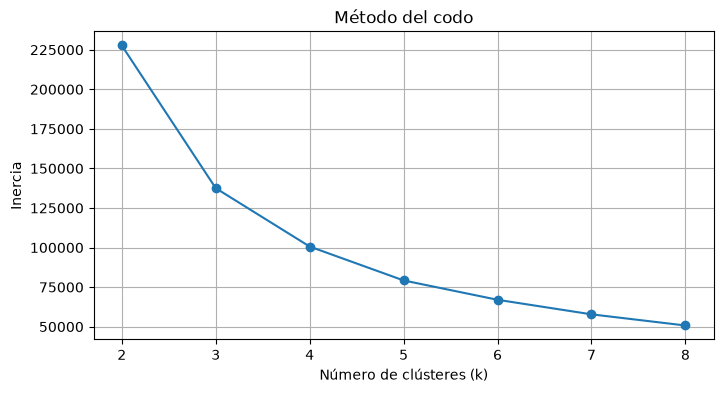

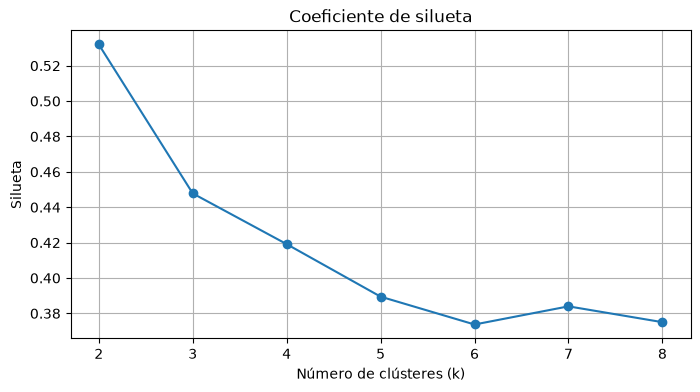

In [32]:
import matplotlib.pyplot as plt

# Gráfica de inercia
plt.figure(figsize=(8, 4))

plt.plot(valores_k, inercias, marker="o")

plt.title("Método del codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(list(valores_k))
plt.grid(True)

plt.show()


# Gráfica de silueta
plt.figure(figsize=(8, 4))

plt.plot(valores_k, siluetas, marker="o")

plt.title("Coeficiente de silueta")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Silueta")
plt.xticks(list(valores_k))
plt.grid(True)

plt.show()

In [33]:
from sklearn.cluster import KMeans

# Entrenar modelo definitivo
modelo_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Obtener clúster para cada viaje
etiquetas = modelo_kmeans.fit_predict(X_escalado)

# Agregar las etiquetas al DataFrame
df_cash["cluster"] = etiquetas

# Consultar cantidad de viajes por clúster
print(df_cash["cluster"].value_counts().sort_index())

cluster
0     62395
1    125521
2     94169
Name: count, dtype: int64


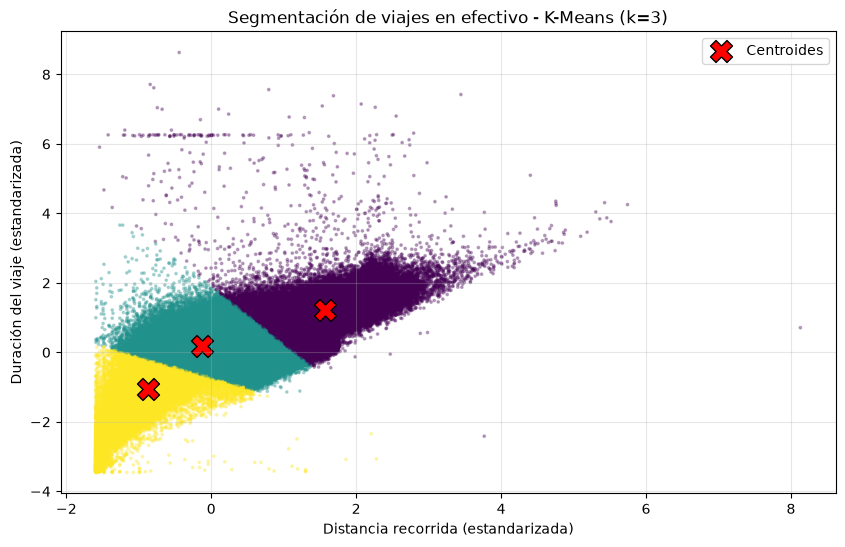

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Graficar los viajes según el clúster asignado
plt.scatter(
    X_escalado[:, 0],
    X_escalado[:, 1],
    c=etiquetas,
    cmap="viridis",
    s=3,
    alpha=0.3
)

# Graficar los centroides
centroides = modelo_kmeans.cluster_centers_

plt.scatter(
    centroides[:, 0],
    centroides[:, 1],
    c="red",
    marker="X",
    s=250,
    edgecolors="black",
    label="Centroides"
)

plt.title("Segmentación de viajes en efectivo - K-Means (k=3)")
plt.xlabel("Distancia recorrida (estandarizada)")
plt.ylabel("Duración del viaje (estandarizada)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [35]:
perfil_clusters = df_cash.groupby("cluster").agg(
    viajes=("trip_distance", "count"),
    distancia_media=("trip_distance", "mean"),
    distancia_mediana=("trip_distance", "median"),
    duracion_media=("trip_duration", "mean"),
    duracion_mediana=("trip_duration", "median")
)

display(perfil_clusters.round(2))

,viajes,distancia_media,distancia_mediana,duracion_media,duracion_mediana
cluster,,,,,
0,62395,11.55,9.81,39.48,31.40
1,125521,2.30,1.94,15.43,14.00
2,94169,0.80,0.76,5.72,5.82


Examen B

In [36]:
# Seleccionar variables del examen B
X_B = df_cash[["trip_duration", "fare_amount"]].copy()

# Consultar estadísticas descriptivas
display(
    X_B.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

,trip_duration,fare_amount
count,282085.000000,282085.000000
mean,17.507243,21.196421
std,40.684025,23.107722
min,0.033333,0.010000
25%,7.400000,8.600000
50%,12.416667,13.500000
75%,20.883333,24.700000
90%,34.050000,45.000000
95%,46.500000,70.000000
99%,70.650000,90.500000


In [37]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Aplicar transformación logarítmica
X_log_B = np.log1p(X_B)

# Estandarizar
scaler_B = StandardScaler()
X_escalado_B = scaler_B.fit_transform(X_log_B)

# Verificar resultados
X_estandarizado_B = pd.DataFrame(
    X_escalado_B,
    columns=X_B.columns
)

display(X_estandarizado_B.describe())

,trip_duration,fare_amount
count,2.820850e+05,2.820850e+05
mean,-2.019147e-16,1.700758e-16
std,1.000002e+00,1.000002e+00
min,-3.458691e+00,-3.924300e+00
25%,-6.439344e-01,-7.667610e-01
50%,-1.492393e-02,-1.885052e-01
75%,6.422437e-01,6.140453e-01
max,8.631030e+00,6.619489e+00


In [38]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

valores_k_B = range(2, 7)

inercias_B = []
siluetas_B = []

for k in valores_k_B:

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_escalado_B)

    inercias_B.append(modelo.inertia_)

    siluetas_B.append(
        silhouette_score(
            X_escalado_B,
            etiquetas,
            sample_size=5000,
            random_state=42
        )
    )

tabla_metricas_B = pd.DataFrame({
    "k": list(valores_k_B),
    "Inercia": inercias_B,
    "Silueta": siluetas_B
})

display(tabla_metricas_B)

,k,Inercia,Silueta
0,2,223232.327973,0.530134
1,3,131398.656608,0.482019
2,4,92371.973759,0.464383
3,5,72810.308136,0.445055
4,6,61793.289142,0.422651


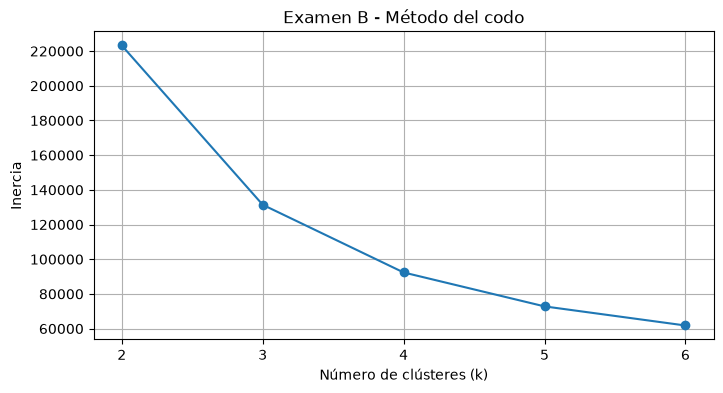

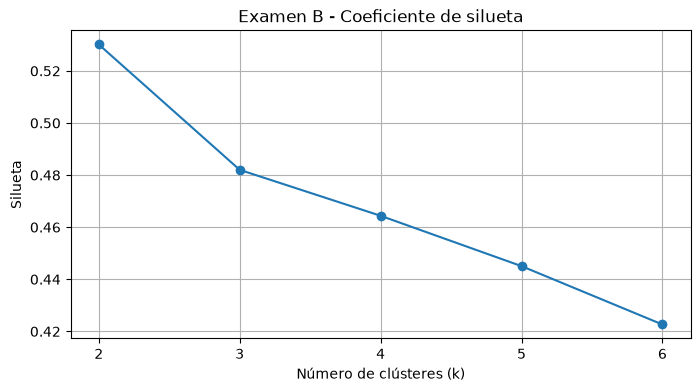

In [39]:
import matplotlib.pyplot as plt

# Método del codo
plt.figure(figsize=(8, 4))
plt.plot(valores_k_B, inercias_B, marker="o")
plt.title("Examen B - Método del codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(list(valores_k_B))
plt.grid(True)
plt.show()

# Coeficiente de silueta
plt.figure(figsize=(8, 4))
plt.plot(valores_k_B, siluetas_B, marker="o")
plt.title("Examen B - Coeficiente de silueta")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Silueta")
plt.xticks(list(valores_k_B))
plt.grid(True)
plt.show()

In [40]:
# Entrenar K-Means para el examen B
modelo_B = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Obtener etiquetas
etiquetas_B = modelo_B.fit_predict(X_escalado_B)

# Asignar los clústeres
df_cash_B = df_cash.copy()
df_cash_B["cluster"] = etiquetas_B

# Consultar distribución
print(df_cash_B["cluster"].value_counts().sort_index())

cluster
0     63076
1    127111
2     91898
Name: count, dtype: int64


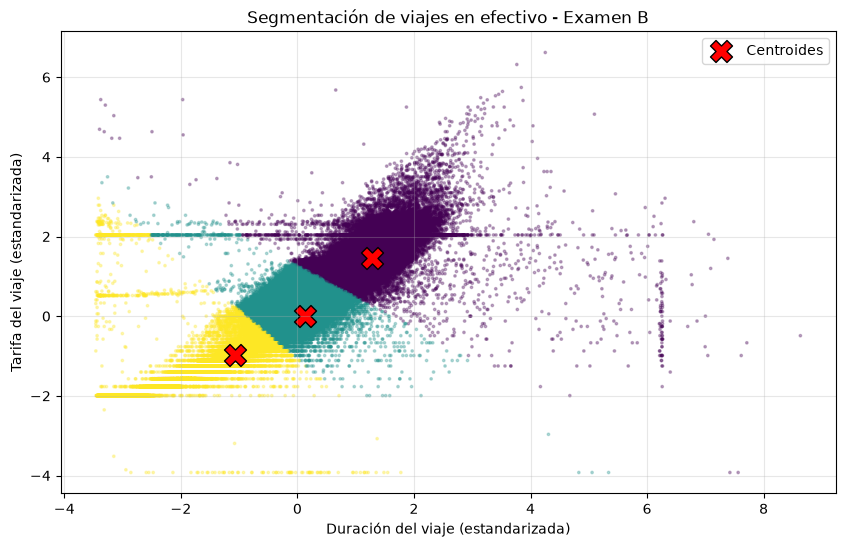

In [41]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_escalado_B[:, 0],
    X_escalado_B[:, 1],
    c=etiquetas_B,
    cmap="viridis",
    s=3,
    alpha=0.3
)

# Centroides
centroides_B = modelo_B.cluster_centers_

plt.scatter(
    centroides_B[:, 0],
    centroides_B[:, 1],
    c="red",
    marker="X",
    s=250,
    edgecolors="black",
    label="Centroides"
)

plt.title("Segmentación de viajes en efectivo - Examen B")
plt.xlabel("Duración del viaje (estandarizada)")
plt.ylabel("Tarifa del viaje (estandarizada)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [42]:
perfil_clusters_B = df_cash_B.groupby("cluster").agg(
    viajes=("trip_duration", "count"),
    duracion_media=("trip_duration", "mean"),
    duracion_mediana=("trip_duration", "median"),
    tarifa_media=("fare_amount", "mean"),
    tarifa_mediana=("fare_amount", "median")
)

display(perfil_clusters_B.round(2))

,viajes,duracion_media,duracion_mediana,tarifa_media,tarifa_mediana
cluster,,,,,
0,63076,40.62,32.13,50.72,42.9
1,127111,14.65,13.70,16.27,14.9
2,91898,5.60,5.77,7.75,7.2


observando una tercer combinacion

In [43]:
# Distribución de las propinas en viajes pagados en efectivo

print("Total de viajes:", len(df_cash))

print(
    "Viajes con propina igual a cero:",
    (df_cash["tip_amount"] == 0).sum()
)

print(
    "Viajes con propina mayor a cero:",
    (df_cash["tip_amount"] > 0).sum()
)

print(
    "Viajes con propina negativa:",
    (df_cash["tip_amount"] < 0).sum()
)

display(df_cash["tip_amount"].describe())

Total de viajes: 282085
Viajes con propina igual a cero: 282070
Viajes con propina mayor a cero: 15
Viajes con propina negativa: 0


count    282085.000000
mean          0.000222
std           0.034036
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           8.860000
Name: tip_amount, dtype: float64

Cambiando a pago con tarjeta

In [44]:
# Seleccionar viajes pagados con tarjeta
df_tarjeta = df_limpio[
    df_limpio["payment_type"] == "Credit card"
].copy()

print("Total de viajes pagados con tarjeta:", len(df_tarjeta))

Total de viajes pagados con tarjeta: 1799462


In [45]:
len(df_cash)

282085

In [46]:
# Obtener una muestra aleatoria del mismo tamaño que Cash
df_tarjeta = df_tarjeta.sample(
    n=282000,
    random_state=42
).copy()

print("Tamaño de la muestra:", df_tarjeta.shape)

Tamaño de la muestra: (282000, 20)


In [47]:
print("Total de viajes:", len(df_tarjeta))

print(
    "Viajes con propina igual a cero:",
    (df_tarjeta["tip_amount"] == 0).sum()
)

print(
    "Viajes con propina mayor a cero:",
    (df_tarjeta["tip_amount"] > 0).sum()
)

print(
    "Viajes con propina negativa:",
    (df_tarjeta["tip_amount"] < 0).sum()
)

display(
    df_tarjeta[["trip_distance", "tip_amount"]].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Total de viajes: 282000
Viajes con propina igual a cero: 26139
Viajes con propina mayor a cero: 255861
Viajes con propina negativa: 0


,trip_distance,tip_amount
count,282000.000000,282000.000000
mean,3.362981,4.291718
std,4.445995,4.152426
min,0.010000,0.000000
25%,1.030000,2.050000
50%,1.730000,3.290000
75%,3.330000,5.000000
90%,8.770000,8.860000
95%,14.010500,13.210000
99%,19.920000,19.450000


In [48]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Seleccionar variables
X_B = df_tarjeta[["trip_distance", "tip_amount"]].copy()

# Transformación logarítmica
X_log_B = np.log1p(X_B)

# Estandarización
scaler_B = StandardScaler()
X_escalado_B = scaler_B.fit_transform(X_log_B)

# Convertir a DataFrame para revisar resultados
X_estandarizado_B = pd.DataFrame(
    X_escalado_B,
    columns=X_B.columns
)

display(X_estandarizado_B.describe())

,trip_distance,tip_amount
count,2.820000e+05,2.820000e+05
mean,-1.068334e-16,-2.368476e-17
std,1.000002e+00,1.000002e+00
min,-1.750568e+00,-2.107841e+00
25%,-7.125497e-01,-4.729297e-01
50%,-2.720170e-01,2.722382e-02
75%,4.138628e-01,5.190610e-01
max,6.209404e+00,4.658250e+00


In [49]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

valores_k_B = range(2, 7)

inercias_B = []
siluetas_B = []

for k in valores_k_B:

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_escalado_B)

    inercias_B.append(modelo.inertia_)

    siluetas_B.append(
        silhouette_score(
            X_escalado_B,
            etiquetas,
            sample_size=5000,
            random_state=42
        )
    )

tabla_metricas_B = pd.DataFrame({
    "k": list(valores_k_B),
    "Inercia": inercias_B,
    "Silueta": siluetas_B
})

display(tabla_metricas_B)

,k,Inercia,Silueta
0,2,283381.028689,0.540749
1,3,173549.735924,0.526165
2,4,117450.104063,0.459720
3,5,95968.994183,0.457390
4,6,78135.755377,0.404510


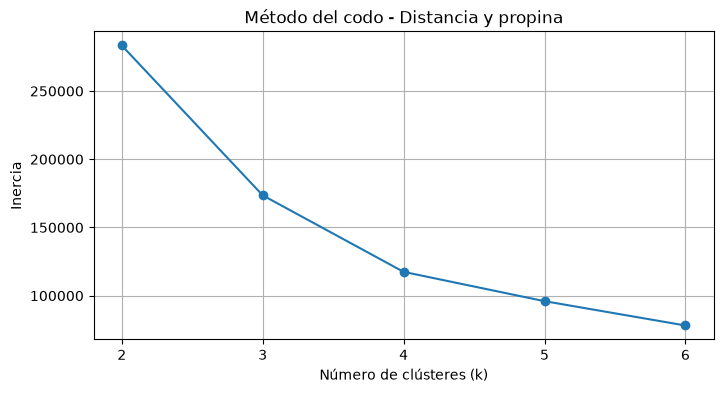

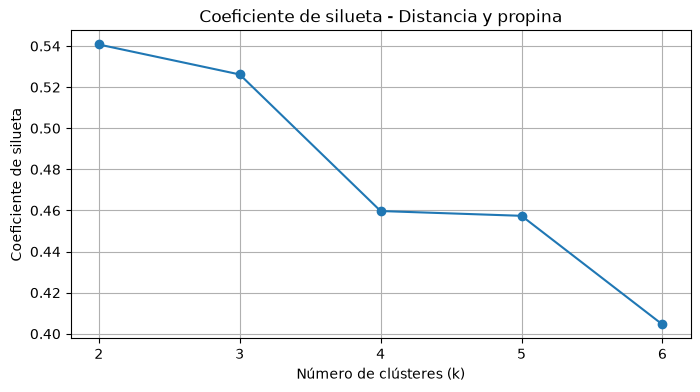

In [50]:
import matplotlib.pyplot as plt

# Gráfica 1: Método del codo (Inercia)
plt.figure(figsize=(8, 4))
plt.plot(valores_k_B, inercias_B, marker="o")

plt.title("Método del codo - Distancia y propina")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(list(valores_k_B))
plt.grid(True)
plt.show()


# Gráfica 2: Coeficiente de silueta
plt.figure(figsize=(8, 4))
plt.plot(valores_k_B, siluetas_B, marker="o")

plt.title("Coeficiente de silueta - Distancia y propina")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Coeficiente de silueta")
plt.xticks(list(valores_k_B))
plt.grid(True)
plt.show()

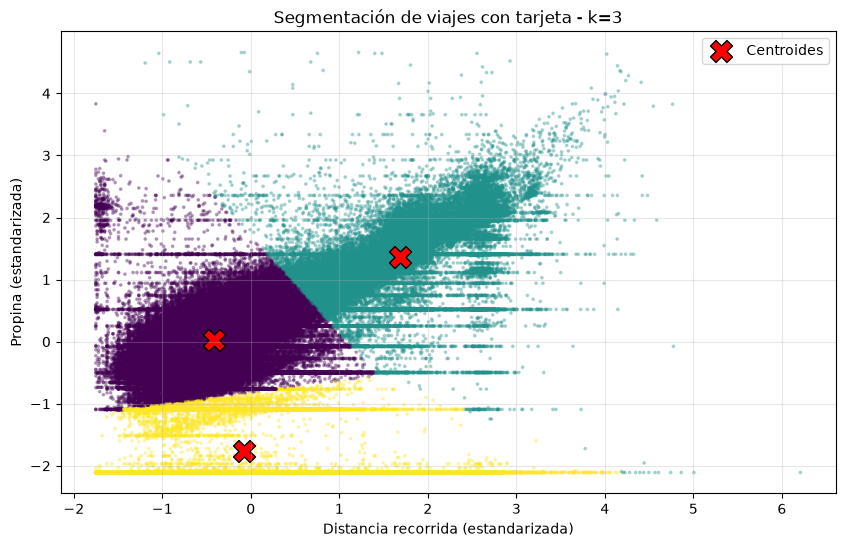

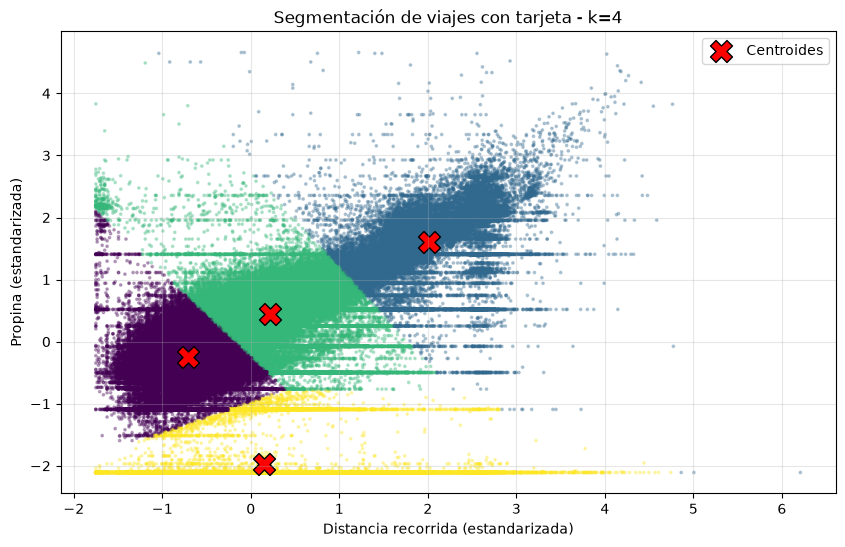

In [51]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

for k in [3, 4]:

    # Entrenar modelo
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_escalado_B)

    # Visualizar clústeres
    plt.figure(figsize=(10, 6))

    plt.scatter(
        X_escalado_B[:, 0],
        X_escalado_B[:, 1],
        c=etiquetas,
        cmap="viridis",
        s=3,
        alpha=0.3
    )

    # Visualizar centroides
    centroides = modelo.cluster_centers_

    plt.scatter(
        centroides[:, 0],
        centroides[:, 1],
        c="red",
        marker="X",
        s=250,
        edgecolors="black",
        label="Centroides"
    )

    plt.title(f"Segmentación de viajes con tarjeta - k={k}")
    plt.xlabel("Distancia recorrida (estandarizada)")
    plt.ylabel("Propina (estandarizada)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

In [52]:
from sklearn.cluster import KMeans

for k in [3, 4]:

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_escalado_B)

    df_resultado = df_tarjeta.copy()
    df_resultado["cluster"] = etiquetas

    perfil = df_resultado.groupby("cluster").agg(
        viajes=("trip_distance", "count"),
        distancia_media=("trip_distance", "mean"),
        distancia_mediana=("trip_distance", "median"),
        propina_media=("tip_amount", "mean"),
        propina_mediana=("tip_amount", "median")
    )

    print(f"\nPerfiles de clústeres para k = {k}")
    display(perfil.round(2))


Perfiles de clústeres para k = 3


,viajes,distancia_media,distancia_mediana,propina_media,propina_mediana
cluster,,,,,
0,192089,1.63,1.42,3.48,3.23
1,48890,10.46,9.00,10.78,9.90
2,41021,3.00,1.70,0.34,0.00



Perfiles de clústeres para k = 4


,viajes,distancia_media,distancia_mediana,propina_media,propina_mediana
cluster,,,,,
0,130307,1.08,1.04,2.68,2.67
1,34496,12.69,10.90,12.57,11.70
2,86170,2.97,2.63,4.92,4.69
3,31027,3.68,2.22,0.13,0.00


Otra exploracion de cash con numero de pasajeros y distancia

In [53]:
# Seleccionar variables para la versión B
X_B = df_cash[["passenger_count", "trip_distance"]].copy()

# Estadísticas descriptivas
display(X_B.describe())

# Frecuencia de pasajeros por viaje
display(
    X_B["passenger_count"]
    .value_counts()
    .sort_index()
)

,passenger_count,trip_distance
count,282085.000000,282085.000000
mean,1.343882,3.842165
std,0.759067,6.214391
min,1.000000,0.010000
25%,1.000000,0.920000
50%,1.000000,1.700000
75%,1.000000,4.370000
max,6.000000,1686.490000


passenger_count
1.0    220318
2.0     39079
3.0     11434
4.0     10321
5.0       571
6.0       362
Name: count, dtype: int64

In [54]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Transformación logarítmica
X_log_B = np.log1p(X_B)

# Estandarización
scaler_B = StandardScaler()
X_escalado_B = scaler_B.fit_transform(X_log_B)

# Verificar resultados
display(
    pd.DataFrame(
        X_escalado_B,
        columns=X_B.columns
    ).describe()
)

,passenger_count,trip_distance
count,2.820850e+05,2.820850e+05
mean,-2.651894e-16,2.111842e-16
std,1.000002e+00,1.000002e+00
min,-4.859776e-01,-1.592439e+00
25%,-4.859776e-01,-7.508596e-01
50%,-4.859776e-01,-3.042097e-01
75%,-4.859776e-01,5.965880e-01
max,4.519712e+00,8.129920e+00


In [55]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

valores_k_B = range(2, 7)

inercias_B = []
siluetas_B = []

for k in valores_k_B:

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_escalado_B)

    inercias_B.append(modelo.inertia_)

    siluetas_B.append(
        silhouette_score(
            X_escalado_B,
            etiquetas,
            sample_size=5000,
            random_state=42
        )
    )

tabla_metricas_B = pd.DataFrame({
    "k": list(valores_k_B),
    "Inercia": inercias_B,
    "Silueta": siluetas_B
})

display(tabla_metricas_B)

,k,Inercia,Silueta
0,2,324581.939870,0.550292
1,3,160363.188416,0.611688
2,4,115075.583100,0.620217
3,5,86895.898261,0.624864
4,6,61144.889106,0.561741


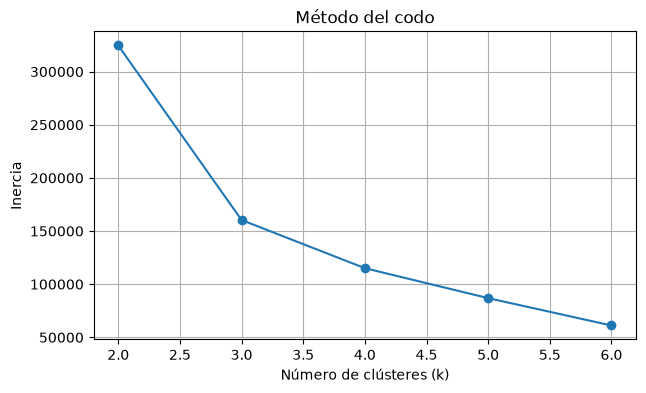

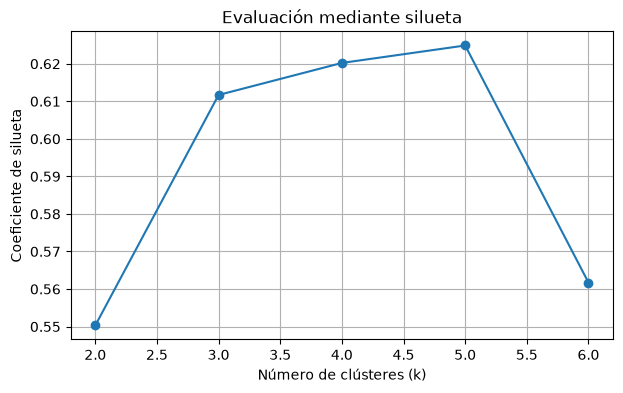

In [56]:
import matplotlib.pyplot as plt

# Gráfica de inercia
plt.figure(figsize=(7, 4))
plt.plot(valores_k_B, inercias_B, marker="o")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.grid(True)
plt.show()

# Gráfica de silueta
plt.figure(figsize=(7, 4))
plt.plot(valores_k_B, siluetas_B, marker="o")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Coeficiente de silueta")
plt.title("Evaluación mediante silueta")
plt.grid(True)
plt.show()

In [57]:
from sklearn.cluster import KMeans

# Comparar los perfiles para k = 4 y k = 5
for k in [4, 5]:

    # Entrenar el modelo
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_escalado_B)

    # Agregar los clústeres al DataFrame original
    df_resultado = df_cash.copy()
    df_resultado["cluster"] = etiquetas

    # Calcular el perfil de cada clúster
    perfil = df_resultado.groupby("cluster").agg(
        viajes=("passenger_count", "count"),
        pasajeros_media=("passenger_count", "mean"),
        pasajeros_mediana=("passenger_count", "median"),
        distancia_media=("trip_distance", "mean"),
        distancia_mediana=("trip_distance", "median")
    )

    # Mostrar resultados
    print(f"\nPerfiles de clústeres para k = {k}")
    display(perfil.round(2))


Perfiles de clústeres para k = 4


,viajes,pasajeros_media,pasajeros_mediana,distancia_media,distancia_mediana
cluster,,,,,
0,160372,1.00,1.0,1.36,1.20
1,59946,1.00,1.0,9.55,7.96
2,18849,2.62,2.0,12.08,10.37
3,42918,2.55,2.0,1.53,1.30



Perfiles de clústeres para k = 5


,viajes,pasajeros_media,pasajeros_mediana,distancia_media,distancia_mediana
cluster,,,,,
0,60035,1.0,1.0,9.54,7.95
1,160283,1.0,1.0,1.36,1.20
2,28514,2.0,2.0,1.58,1.31
3,16904,3.6,4.0,1.97,1.48
4,16349,2.5,2.0,13.14,11.51


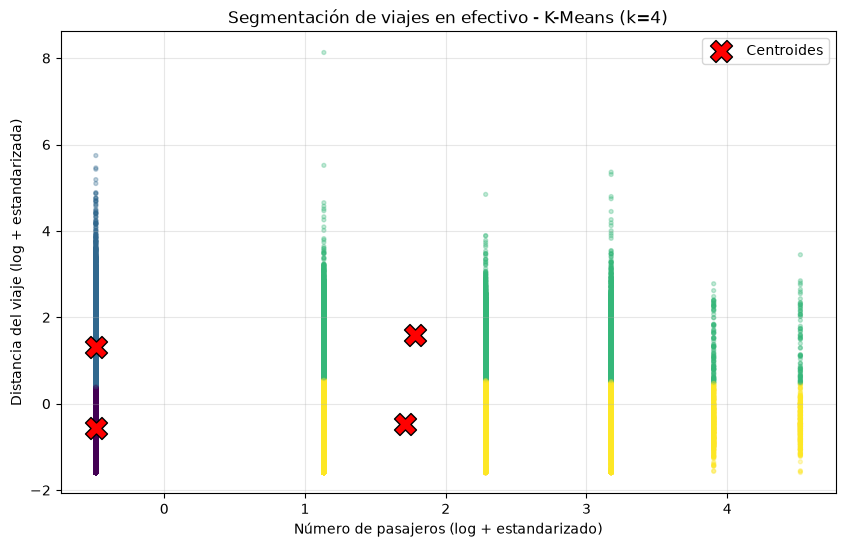

In [58]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Entrenar K-Means con k = 4
modelo_B = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

etiquetas_B = modelo_B.fit_predict(X_escalado_B)

# Obtener los centroides
centroides_B = modelo_B.cluster_centers_

# Gráfica de dispersión
plt.figure(figsize=(10, 6))

plt.scatter(
    X_escalado_B[:, 0],
    X_escalado_B[:, 1],
    c=etiquetas_B,
    cmap="viridis",
    s=8,
    alpha=0.3
)

# Dibujar centroides
plt.scatter(
    centroides_B[:, 0],
    centroides_B[:, 1],
    c="red",
    marker="X",
    s=250,
    edgecolors="black",
    label="Centroides"
)

plt.xlabel("Número de pasajeros (log + estandarizado)")
plt.ylabel("Distancia del viaje (log + estandarizada)")
plt.title("Segmentación de viajes en efectivo - K-Means (k=4)")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

Mapeo de codigos de tipy de pago

In [1]:
import pandas as pd

In [2]:
ruta = "../data/raw/nyc_taxi_examen.csv"
df = pd.read_csv(ruta)

In [3]:
# Diccionario de tipos de pago
tipos_pago = {
    1: "Credit card",
    2: "Cash",
    3: "No charge",
    4: "Dispute"
}

# Reemplazar códigos por descripciones
df["payment_type"] = df["payment_type"].map(tipos_pago)

In [4]:
df.to_csv(ruta)